In [1]:
# Instale através do requirements.txt: pip install -r requirements.txt

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn as skl
import tensorflow as tf

I0000 00:00:1794170514.113675    2530 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794170515.309133    2530 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794170519.198004    2530 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
# Obtendo o dataset
df = pd.read_csv("../data/base_classificacao_binaria.csv")

# Etapa 1: Entendimento do Problema

### Tipo de problema
O desenvolvimento do projeto toma como base o dataset ```base_classificacao_binaria.csv``` (recorte do dataset abaixo) e se fundamenta no aprendizado supervisionado, dado que cada amostra possui seu respectivo rótulo de saída (```target```). Além disso, se trata de um problema de classificação, em que o modelo deve identificar os padrões nos atributos de entrada para determinar a qual classe discreta (binária, neste caso) a amostragem pertence.

### Features e Labels
O dataset já nos dá um norte bem forte sobre quais métricas escolher como ```features``` e qual escolher como ```label```. No nosso dataset temos um total de 13 colunas, sendo 11 delas numéricas, 1 de índice de 1 de dados em string. A última coluna é uma coluna de valores binários chamada de ```target```, e é justamente o que queremos prever com base nos dados das colunas anteriores. 

Sabendo disso, iremos adotar as seguintes _features_:
```sensor_a```, ```sensor_b```, ```sensor_c```, ```measurement_d```, ```measurement_e```, ```measurement_f```, ```measurement_g```, ```measurement_h```, ```measurement_j```, ```ratio_j``` e ```environment```.
Nosso _label_ será a coluna ```target```.



In [3]:
# Data sample
df.head()
#df.describe()

,sample_id,sensor_a,sensor_b,sensor_c,measurement_d,measurement_e,measurement_f,measurement_g,measurement_h,measurement_i,ratio_j,environment,target
0,S08268,8.914515,867.306001,0.019069,NaN,45.686368,1.700616,-0.902463,NaN,0.453651,1.017578,hot,0
1,S03978,6.648553,1092.307380,0.029332,NaN,53.110799,-0.208217,-2.485422,-1.579362,0.971668,3.516217,hot,0
2,S03450,10.803832,952.510306,0.055172,0.644110,50.427537,2.361744,NaN,-0.285890,0.326307,1.623479,hot,1
3,S00187,8.140751,669.676350,0.063204,1.174591,55.814057,0.740185,-2.444912,-1.822998,NaN,0.733792,mild,1
4,S02910,8.351185,1302.375048,0.046524,0.674800,55.144315,0.530997,-0.405251,NaN,-0.755999,0.716739,cold,0


# Etapa 2: Análise Exploratória de Dados

Nesta etapa, será realizado um diagnóstico para verificar a qualidade e a integridade dos dados do dataset. Faremos isso por meio de análises gráficas e quantitativas dos dados através das bibliotecas ```pandas``` e ```matplotlib```, se aproveitando de histogramas (para verificar a distribuição), _box-plots_ (para verificar a existência de _outliers_), ferramentas para identificar inconsistências (valores nulos ou repetidos) e plotar uma matriz de correlação que vai nos dizer quais métricas possuem correlação forte/fraca.

## Etapa 2.1: Análise de distribuição dos dados através de histogramas
Nesta etapa, será realizada uma análise da distribuição dos dados utilizando histogramas. As informações que os histogramas nos dão são valiosas, uma vez que a partir dele conseguimos detectar discrepâncias entre as medidas de cada coluna e se elas seguem uma distribuição normal (importante para as etapas de imputação e escalonamento dos dados). 

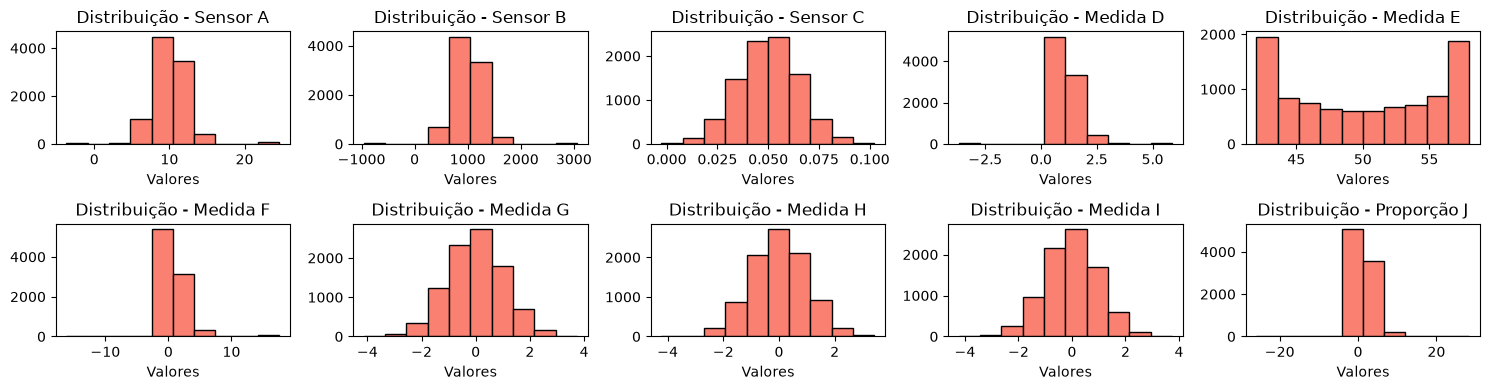

In [4]:
# Histogramas

fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(15, 4))

axes[0][0].hist(df["sensor_a"], color="salmon", edgecolor="black")
axes[0][0].set_title("Distribuição - Sensor A")
axes[0][0].set_xlabel("Valores")

axes[0][1].hist(df["sensor_b"], color="salmon", edgecolor="black")
axes[0][1].set_title("Distribuição - Sensor B")
axes[0][1].set_xlabel("Valores")

axes[0][2].hist(df["sensor_c"], color="salmon", edgecolor="black")
axes[0][2].set_title("Distribuição - Sensor C")
axes[0][2].set_xlabel("Valores")

axes[0][3].hist(df["measurement_d"], color="salmon", edgecolor="black")
axes[0][3].set_title("Distribuição - Medida D")
axes[0][3].set_xlabel("Valores")

axes[0][4].hist(df["measurement_e"], color="salmon", edgecolor="black")
axes[0][4].set_title("Distribuição - Medida E")
axes[0][4].set_xlabel("Valores")

axes[1][0].hist(df["measurement_f"], color="salmon", edgecolor="black")
axes[1][0].set_title("Distribuição - Medida F")
axes[1][0].set_xlabel("Valores")

axes[1][1].hist(df["measurement_g"], color="salmon", edgecolor="black")
axes[1][1].set_title("Distribuição - Medida G")
axes[1][1].set_xlabel("Valores")

axes[1][2].hist(df["measurement_h"], color="salmon", edgecolor="black")
axes[1][2].set_title("Distribuição - Medida H")
axes[1][2].set_xlabel("Valores")

axes[1][3].hist(df["measurement_i"], color="salmon", edgecolor="black")
axes[1][3].set_title("Distribuição - Medida I")
axes[1][3].set_xlabel("Valores")

axes[1][4].hist(df["ratio_j"], color="salmon", edgecolor="black")
axes[1][4].set_title("Distribuição - Proporção J")
axes[1][4].set_xlabel("Valores")

plt.tight_layout()
plt.show()

## Interpretação dos gráficos

- **Distribuições normais (Gaussianas)**: As variáveis ``sensor_c``, ``measurement_g``, ``measurement_h`` e ``measurement_i`` apresentam o formato clássico de "sino", com os dados concentrados em torno da média. Para essas variáveis, imputar valores nulos usando a média é uma boa estratégia (Etapa 3), e elas responderão muito bem ao StandardScaler (Etapa 4).

- **Distribuições Asssimétricas**: O ``sensor_a``, ``sensor_b``, ``measurement_d``, ``measurement_f`` e ``ratio_j`` possuem picos acentuados e caudas longas (assimetria). O uso da mediana pode ser mais seguro para a imputação de nulos nessas colunas (Etapa 3).

- **Distribuição Bimodal**: A ``measurement_e`` foge completamente do padrão das outras medidas e apresenta uma distribuição bimodal com picos nas pontas. Essa variável não possui uma tendência central clara.

## Etapa 2.2: Análise de _outliers_ através de boxplots.

Os boxplots em subgráficos individuais permitem visualizar discrepâncias que não eram óbvias no gráfico unificado.

sensor_a            Axes(0.125,0.53;0.133621x0.35)
sensor_b         Axes(0.285345,0.53;0.133621x0.35)
sensor_c          Axes(0.44569,0.53;0.133621x0.35)
measurement_d    Axes(0.606034,0.53;0.133621x0.35)
measurement_e    Axes(0.766379,0.53;0.133621x0.35)
measurement_f       Axes(0.125,0.11;0.133621x0.35)
measurement_g    Axes(0.285345,0.11;0.133621x0.35)
measurement_h     Axes(0.44569,0.11;0.133621x0.35)
measurement_i    Axes(0.606034,0.11;0.133621x0.35)
ratio_j          Axes(0.766379,0.11;0.133621x0.35)
dtype: object

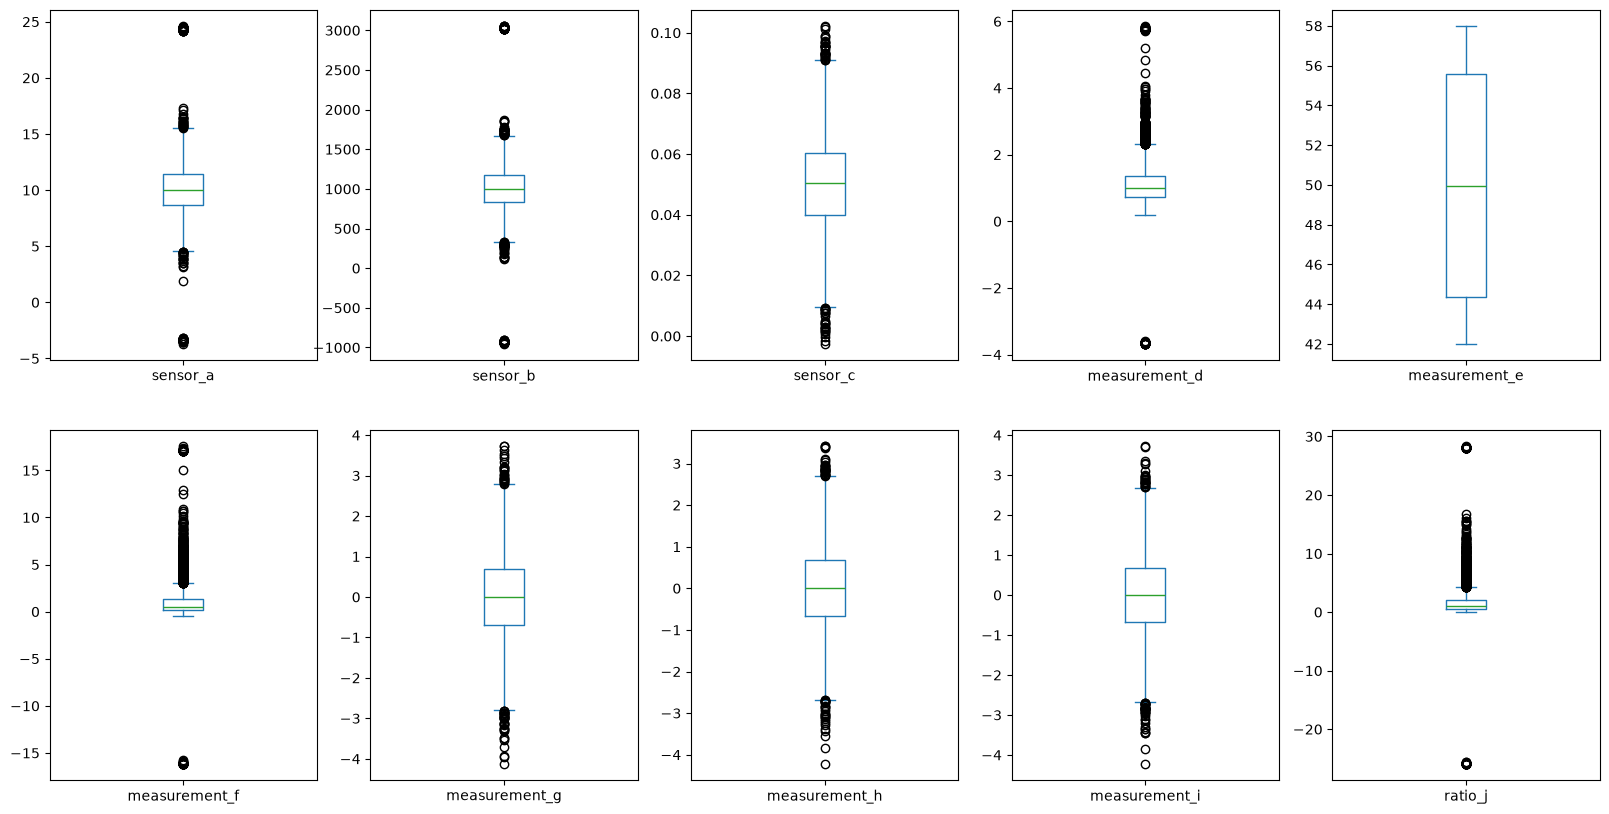

In [31]:
# boxplots
crop = df.drop(['target', 'encoded_environment'], axis=1)
crop.plot(kind='box', subplots=True, layout=(2, 5), figsize=(20, 10), sharey=False)

## Interpretação dos gráficos:

- **Presença de Outliers**: Com exceção da ``measurement_e`` (que não apresenta pontos fora dos limites dos "bigodes"), todas as outras variáveis possuem outliers significativos em ambas as direções (valores extremos muito altos e muito baixos).

- **Impacto no Escalonamento**: A presença severa de outliers no ``sensor_b``, ``measurement_f`` e ``ratio_j`` sugere que essas variáveis podem distorcer o cálculo da média e da variância. O escalonamento padrão (``StandardScaler``) será afetado, pois ele é sensível a extremos.

## Etapa 2.3: Análise de variáveis com correlação positiva através da Matriz de Correlação

<StringArray>
['hot', 'mild', 'cold', nan]
Length: 4, dtype: str


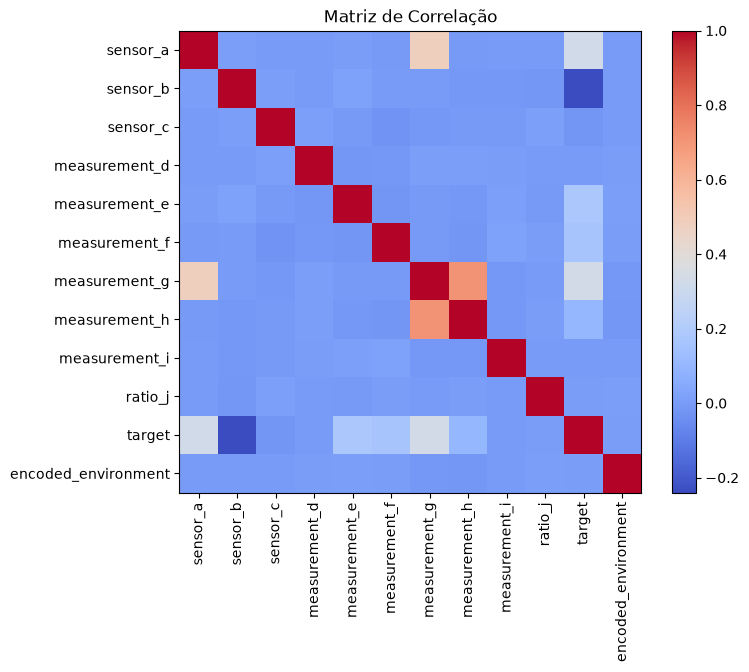

In [23]:
# fazendo encoding da coluna [environment]
# a coluna environment pode assumir 3 valores: hot, mild e cold. Podemos mapear cada valor deste para um número inteiro.
print(df["environment"].unique())

def encoding(df):
    if df['environment'] == 'hot': 
        return 2
    if df['environment'] == 'mild': 
        return 1
    if df['environment'] == 'cold': 
        return 0
    return df['environment']

# cria a coluna 'encoded_environment' com os valores codificados
df['encoded_environment'] = df.apply(encoding, axis=1)

# # Matriz de correlação linear (Pearson)
corr_matrix_crop = df.drop(["sample_id", "environment"], axis=1)
corr_matrix = corr_matrix_crop.corr()

# # Visualização simples da matriz
plt.figure(figsize=(8, 6))
plt.imshow(corr_matrix, cmap='coolwarm', interpolation='none')
plt.colorbar()
plt.xticks(range(len(corr_matrix)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix)), corr_matrix.columns)
plt.title("Matriz de Correlação")
plt.show()

# Interpretação dos dados:

- **As variáveis mais preditivas**: O ``sensor_b`` é a feature com maior correlação linear (negativa, tom azul escuro) com a variável ``target``. O ``sensor_a`` e a ``measurement_e`` também mostram alguma correlação positiva (tons mais claros de azul/branco) com o ``target``.

- **Multicolinearidade**: Temos uma forte correlação positiva (tom salmão) entre ``measurement_g`` e ``measurement_h`` e uma correlação moderada entre ``sensor_a`` e ``measurement_g``.

## Etapa 2.4: análise de correlação entre variáveis através do gráfico de dispersão.

Como pudemos ver na matriz de correlação , algumas variáveis possuem correlação positiva (``measurement_g``/``measurement_h`` e ``sensor_a``/``measurement_g``). Podemos plotar o gráfico de dispersão destas variáveis para identificar o nível de correlação entre elas.

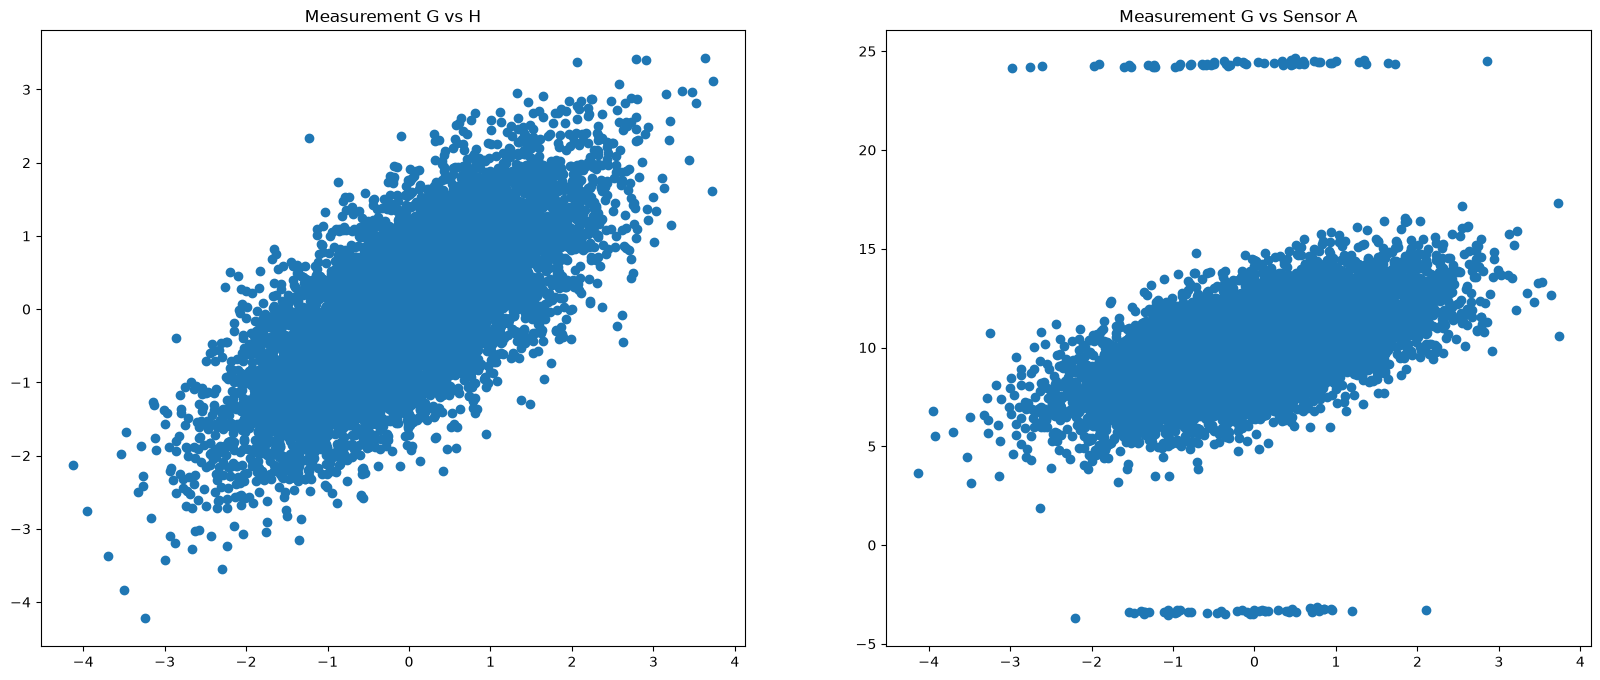

In [43]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(20, 8))

axes[0].scatter(df['measurement_g'], df['measurement_h'])
axes[0].set_title('Measurement G vs H')

axes[1].scatter(df['measurement_g'], df['sensor_a'])
axes[1].set_title('Measurement G vs Sensor A')

plt.show()

## Interpretação dos gráficos:

- Embora a massa central de pontos mostre a correlação positiva moderada, a dispersão nos mostra um problema no sensor_a: existem duas linhas de valores extremos perfeitamente agrupadas na horizontal (uma no topo, perto de 24, e outra na base, perto de -4). Isso sugere que o sensor sofreu saturação física (atingiu o limite máximo/mínimo de medição) ou que ocorreu uma falha técnica na recolha dos dados.

# Etapa 3: Tratamento de Dados Faltantes